# Which crayon bundles sell more?

Tallow Creek Crayon Co. is a **fictional** crayon maker. It sells eight crayon bundles through 60 stores, and its sales team asked a simple question: *which bundles sell more?*

The answer depends on what you divide by. Here it is three ways:

1. **Total units**, which is what the sales report shows.
2. **Units per store-week**, which corrects for how many shelves a bundle is on.
3. **Like-for-like sales from a model**: what each bundle would sell in the same stores, in the same weeks, at its list price, with no promotion.

The three answers disagree, and the disagreement is the finding. After the ranking, the study looks at price sensitivity, at whether promotions pay for themselves once trade spend is counted, and at what wider distribution of the best bundle would be worth.

Because the data is generated, the true demand behind it is known and saved in `data/answer_key/`. **Nothing in the analysis reads it.** It is opened only in section 8, to check the answers.

> Everything here is invented: the company, the stores and every number.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import analysis as A
import plots as P

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

s, bundles, stores = A.load()
names = bundles.set_index("bundle_id").name
print(f"{len(s):,} store-bundle-weeks from {s.week_start.min():%b %d, %Y} to "
      f"{s.week_start.max():%b %d, %Y}: {s.units.sum():,} boxes sold, "
      f"${s.trade_spend.sum():,.0f} of trade spend.")

33,872 store-bundle-weeks from Jan 01, 2024 to Dec 22, 2025: 187,848 boxes sold, $22,190 of trade spend.


## 1. The data

Three tables. **Bundles**: list price (raised on three bundles in 2025), the wholesale price the factory charges retailers, and unit cost. **Stores**: 60 stores in four channels. **Weekly sales**: one row per store, bundle and week the bundle was on the shelf, with the shelf price, whether it was on promotion or on an end-cap display, units sold, and the trade spend the factory paid.

The trade terms: on a promotion, the factory refunds the retailer **half of the discount** on every unit sold (a scan-down) and pays **$3 per store-week** on display.

In [2]:
bundles

,bundle_id,name,crayons,theme,list_price,list_price_2025,wholesale_price,unit_cost,launch_week
0,B01,Classic 8,8,primary,1.99,2.09,1.05,0.38,2024-01-01
1,B02,Classic 24,24,primary,3.49,3.69,1.85,0.80,2024-01-01
2,B03,Pastel Garden 16,16,themed,2.99,2.99,1.60,0.62,2024-01-01
3,B04,Ocean & Sky 16,16,themed,2.99,2.99,1.60,0.62,2024-01-01
4,B05,Neon Pop 12,12,novelty,2.79,2.79,1.45,0.66,2024-01-01
5,B06,Metallic Shine 12,12,novelty,4.49,4.49,2.45,0.95,2024-01-01
6,B07,Skin Tones 24,24,skin tones,3.99,3.99,2.15,0.85,2024-09-09
7,B08,Big Box 64,64,assorted,7.99,8.49,4.30,2.10,2024-01-01


In [3]:
s.head()

,week_start,store_id,bundle_id,regular_price,shelf_price,on_promo,on_display,units,trade_spend,channel,bts,holiday,log_price_ratio
0,2024-01-01,S001,B01,1.82,1.82,0,0,6,0.0,Big-box,0,0,-0.089298
1,2024-01-01,S001,B02,3.47,3.47,0,0,9,0.0,Big-box,0,0,-0.005747
2,2024-01-01,S001,B03,2.77,2.77,0,0,8,0.0,Big-box,0,0,-0.076426
3,2024-01-01,S001,B05,2.46,2.46,0,0,7,0.0,Big-box,0,0,-0.125880
4,2024-01-01,S001,B06,4.15,4.15,0,0,7,0.0,Big-box,0,0,-0.078744


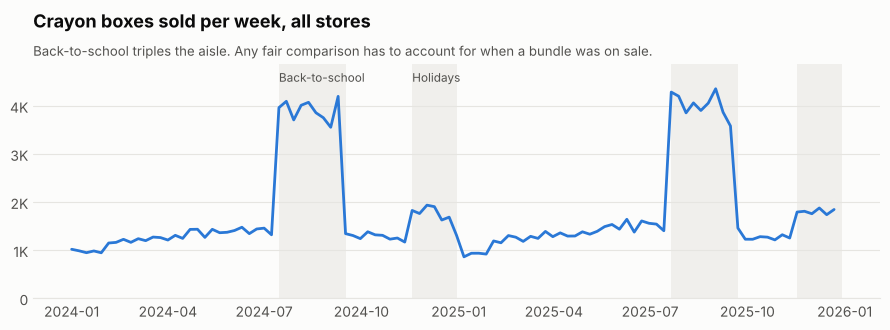

In [4]:
P.weekly_units(s, "../reports/figures/weekly_units.png");

The crayon aisle triples at back-to-school, with a smaller bump at the holidays. Any bundle that spent more of its life in those weeks, or less, will look better or worse than it is.

## 2. Answer one: total units

In [5]:
naive = A.naive_table(s, bundles)
naive[["name", "units", "stores", "store_weeks", "promo_share", "trade_spend", "gross_profit"]] \
    .sort_values("units", ascending=False).round(2)

,name,units,stores,store_weeks,promo_share,trade_spend,gross_profit
bundle_id,,,,,,,
B02,Classic 24,54586,60,6240,0.10,7211.78,50103.52
B01,Classic 8,46647,60,6240,0.09,4357.90,26895.59
B05,Neon Pop 12,21282,51,5304,0.16,4912.34,11900.44
B03,Pastel Garden 16,15303,42,4368,0.06,1601.55,13395.39
B04,Ocean & Sky 16,15254,36,3744,0.06,1356.04,13592.88
B07,Skin Tones 24,13232,30,1632,0.03,616.97,16584.63
B06,Metallic Shine 12,10863,27,2808,0.01,386.44,15908.06
B08,Big Box 64,10681,34,3536,0.04,1747.39,21750.81


By the sales report, **Classic 24** wins, **Neon Pop 12** is a strong third, and **Skin Tones 24** is sixth.

But the table already shows why that ranking is unfair. Skin Tones 24 launched in September 2024 and is on 30 shelves, against 60 for the Classics, so it has a quarter of their store-weeks. Neon Pop spent 16% of its weeks on promotion, the most of any bundle. Total units measure *how much opportunity a bundle had* as much as how well it sells.

## 3. Answer two: units per store-week (velocity)

In [6]:
naive[["name", "velocity", "units"]].sort_values("velocity", ascending=False).round(2)

,name,velocity,units
bundle_id,,,
B02,Classic 24,8.75,54586
B07,Skin Tones 24,8.11,13232
B01,Classic 8,7.48,46647
B04,Ocean & Sky 16,4.07,15254
B05,Neon Pop 12,4.01,21282
B06,Metallic Shine 12,3.87,10863
B03,Pastel Garden 16,3.50,15303
B08,Big Box 64,3.02,10681


Dividing by store-weeks moves **Skin Tones 24 to second place**. Velocity is the measure most sales teams graduate to, and it is better. It still mixes in three things that have nothing to do with how good a bundle is:

In [7]:
mix = s.assign(big_store=s.channel.isin(["Big-box", "School & office"]))
pd.DataFrame({
    "name": names,
    "share_in_big_stores": mix.groupby("bundle_id").big_store.mean(),
    "share_on_promo": mix.groupby("bundle_id").on_promo.mean(),
    "share_on_display": mix.groupby("bundle_id").on_display.mean(),
    "share_in_back_to_school": mix.groupby("bundle_id").bts.mean(),
}).round(2)

,name,share_in_big_stores,share_on_promo,share_on_display,share_in_back_to_school
bundle_id,,,,,
B01,Classic 8,0.40,0.09,0.08,0.17
B02,Classic 24,0.40,0.10,0.08,0.17
B03,Pastel Garden 16,0.45,0.06,0.06,0.17
B04,Ocean & Sky 16,0.36,0.06,0.05,0.17
B05,Neon Pop 12,0.35,0.16,0.12,0.17
B06,Metallic Shine 12,0.89,0.01,0.03,0.17
B07,Skin Tones 24,0.25,0.03,0.03,0.18
B08,Big Box 64,0.71,0.04,0.04,0.17


- **Where it sits.** Metallic Shine 12 (89% of its weeks) and Big Box 64 (71%) are mostly in big-box and school-supply stores, which have far more traffic, so part of their velocity is really the store's. Skin Tones 24 is the opposite: only 25% of its weeks are in big stores, so velocity *understates* it.
- **How often it was promoted.** Neon Pop's promotions inflate its average week.
- **When it was on sale.** Not a problem here: every bundle spent about 17-18% of its weeks in back-to-school, including Skin Tones 24, which caught all of the 2025 season. In other data this is often the biggest distortion of all.

Velocity can't separate these from the bundle itself. A model can.

## 4. Answer three: like-for-like sales

A Poisson regression on weekly units, with:

| Term | What it absorbs |
|---|---|
| Store effects | each store's traffic, whatever it carries |
| Week effects | the crayon calendar, shared by all bundles |
| Bundle effects | **the thing we want** |
| Bundle × back-to-school, bundle × holidays | bundles that peak harder in a season (Big Box at Christmas, the Classics in August) |
| Bundle × log(price) | a price elasticity for each bundle |
| Display | the lift from an end-cap |

Standard errors are clustered by store, because weeks in the same store are not independent and the counts are noisier than a Poisson assumes.

From the fitted model, *like-for-like sales* is the expected units per store-week **if all 60 stores had carried the bundle for all 104 weeks, at its 2024 list price, with no promotion and no display**. Same stores, same weeks, same conditions for every bundle.

### Checking the model before trusting it

A model is only as good as what it was told about. One way to check: compare what it predicted with what actually sold, cell by cell. Here, by bundle and channel:

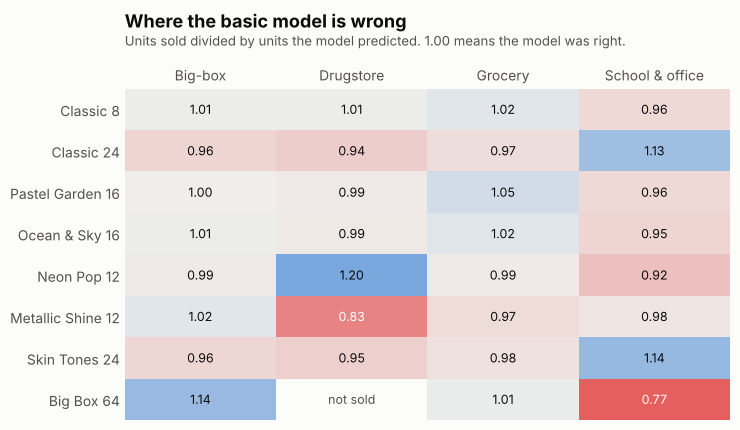

In [8]:
basic = A.DemandModel(s)
resid_basic = A.channel_residuals(basic)
P.channel_heatmap(resid_basic, names, "../reports/figures/channel_residuals.png");

A well-specified model would show about 1.00 everywhere. This one is off by up to 23% in a clear pattern: **Classic 24 and Skin Tones 24 sell better in school-supply stores, Neon Pop sells better in drugstores, Big Box 64 sells better in big-box stores.** The basic model assumes a bundle performs the same everywhere, relative to the store's traffic. It doesn't.

This matters beyond the ranking. Big-box stores are also the cheapest channel, so a model that doesn't know Big Box 64 is *preferred* there sees it selling more where it is cheaper and concludes it is very price-sensitive. That is omitted-variable bias, and section 5 shows it.

The fix is a term for each bundle in each channel:

In [9]:
model = A.DemandModel(s, channel_bundle=True)
A.channel_residuals(model).round(2)

channel,Big-box,Drugstore,Grocery,School & office
bundle_id,,,,
B01,1.0,1.0,1.0,1.0
B02,1.0,1.0,1.0,1.0
B03,1.0,1.0,1.0,1.0
B04,1.0,1.0,1.0,1.0
B05,1.0,1.0,1.0,1.0
B06,1.0,1.0,1.0,1.0
B07,1.0,1.0,1.0,1.0
B08,1.0,NaN,1.0,1.0


Flat. (Big Box 64 has never been sold in a drugstore, so there is nothing to check there, and the model assumes it would sell in drugstores the way it sells in grocery stores. That's an assumption, not a finding.)

### The like-for-like ranking

In [10]:
ci = model.baseline_velocity_ci(1000)
like = ci.assign(name=names, unit_margin=naive.unit_margin)
like["margin_per_store_week"] = like.estimate * like.unit_margin
like.sort_values("estimate", ascending=False).round(2)

,estimate,low,high,name,unit_margin,margin_per_store_week
B07,9.25,9.02,9.53,Skin Tones 24,1.30,12.02
B02,8.02,7.92,8.13,Classic 24,1.05,8.42
B01,6.71,6.62,6.81,Classic 8,0.67,4.50
B04,3.86,3.77,3.96,Ocean & Sky 16,0.98,3.78
B05,3.20,3.14,3.28,Neon Pop 12,0.79,2.53
B03,3.14,3.08,3.22,Pastel Garden 16,0.98,3.08
B06,2.61,2.58,2.65,Metallic Shine 12,1.50,3.92
B08,2.26,2.20,2.34,Big Box 64,2.20,4.98


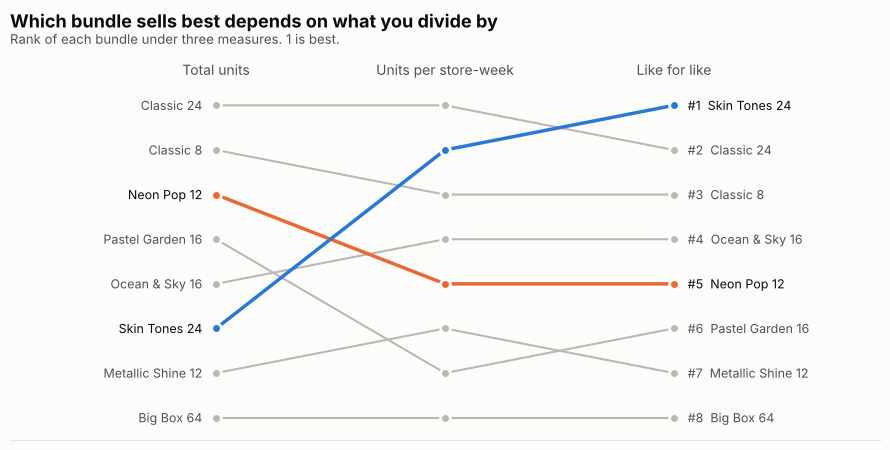

In [11]:
table = pd.DataFrame({"Total units": naive.units,
                      "Units per store-week": naive.velocity,
                      "Like for like": ci.estimate})
table.index = names.reindex(table.index)
P.three_rankings(table, {"Skin Tones 24": P.BLUE, "Neon Pop 12": P.ORANGE},
                 "../reports/figures/three_rankings.png");

**Skin Tones 24 is the best-selling bundle in the line**, like for like: about 9 boxes per store-week against about 8 for Classic 24, and the 95% intervals don't overlap. It looked sixth only because it is on half the shelves and arrived late.

**Neon Pop 12 is a mid-table bundle**, fifth like for like. Its third place in total units came from being on more shelves than most and from being promoted the most.

## 5. Price sensitivity

In [12]:
el = pd.concat({"basic model": basic.elasticities(), "with channel terms": model.elasticities()},
               axis=1).round(2)
el.insert(0, "name", names)
el

name basic model             with channel terms            
                                estimate   low  high           estimate   low  high
bundle_id                                                                          
B01                Classic 8       -2.30 -2.48 -2.12              -2.30 -2.48 -2.12
B02               Classic 24       -1.93 -2.07 -1.78              -1.91 -2.06 -1.76
B03         Pastel Garden 16       -1.74 -1.94 -1.54              -1.78 -1.98 -1.59
B04           Ocean & Sky 16       -1.68 -1.93 -1.43              -1.69 -1.96 -1.43
B05              Neon Pop 12       -2.55 -2.73 -2.37              -2.66 -2.83 -2.49
B06        Metallic Shine 12       -1.51 -1.94 -1.08              -1.22 -1.70 -0.73
B07            Skin Tones 24       -1.71 -2.08 -1.33              -1.55 -1.96 -1.13
B08               Big Box 64       -2.11 -2.40 -1.81              -1.67 -1.99 -1.36

Elasticity is the percentage change in units for a 1% change in shelf price. Translated into a 10% discount:

In [13]:
el_now = model.elasticities().estimate
pd.DataFrame({"name": names, "elasticity": el_now.round(2),
              "extra_units_from_10pct_discount": (0.9 ** el_now - 1).map("{:+.0%}".format)})

,name,elasticity,extra_units_from_10pct_discount
bundle_id,,,
B01,Classic 8,-2.30,+27%
B02,Classic 24,-1.91,+22%
B03,Pastel Garden 16,-1.78,+21%
B04,Ocean & Sky 16,-1.69,+20%
B05,Neon Pop 12,-2.66,+32%
B06,Metallic Shine 12,-1.22,+14%
B07,Skin Tones 24,-1.55,+18%
B08,Big Box 64,-1.67,+19%


A 10% discount sells about 32% more Neon Pop 12, but only about 14% more Metallic Shine 12.

The two models agree on most bundles but not on **Big Box 64** (about −2.1 in the basic model, −1.7 with channel terms) or **Skin Tones 24** (−1.71 against −1.55). This is the bias from section 4: ignore where a bundle is preferred, and you misread price sensitivity. Any pricing decision built on the basic model would have discounted Big Box more than it deserves.

The least price-sensitive bundles, **Metallic Shine 12 and Skin Tones 24**, are where a price increase would cost the fewest units. This model measures shelf prices, so a wholesale increase only behaves this way if retailers pass it through.

## 6. Do promotions pay?

First, the comparison most teams make: average units in promoted weeks divided by average units in other weeks.

In [14]:
roi = A.promo_roi(model, s, bundles)
pd.DataFrame({"name": names, "naive_lift": A.naive_promo_lift(s),
              "model_lift": roi.model_lift}).round(2)

,name,naive_lift,model_lift
bundle_id,,,
B01,Classic 8,3.15,2.34
B02,Classic 24,2.81,2.14
B03,Pastel Garden 16,2.51,2.09
B04,Ocean & Sky 16,2.41,1.95
B05,Neon Pop 12,3.43,2.76
B06,Metallic Shine 12,2.18,1.75
B07,Skin Tones 24,2.36,1.92
B08,Big Box 64,2.79,1.99


The naive lift overstates every bundle, by roughly 0.4 to 0.8. Promotions were planned into back-to-school, when everything sells more anyway, so the naive comparison credits the promotion with the season. The model compares each promoted week with what the same store would have sold that same week at the regular price, off display.

Now the money. For every promoted or displayed store-week: the extra units over that baseline, times the factory's margin per unit, against the trade spend.

In [15]:
roi[["name", "events", "units", "baseline_units", "incremental_units",
     "incremental_profit", "trade_spend", "net_return", "roi"]].round(2)

,name,events,units,baseline_units,incremental_units,incremental_profit,trade_spend,net_return,roi
bundle_id,,,,,,,,,
B01,Classic 8,701,12389,5286.47,7102.53,4758.69,4357.90,400.79,0.09
B02,Classic 24,721,13855,6479.79,7375.21,7743.97,7211.78,532.19,0.07
B03,Pastel Garden 16,360,2655,1272.39,1382.61,1354.96,1601.55,-246.59,-0.15
B04,Ocean & Sky 16,293,2452,1255.42,1196.58,1172.64,1356.04,-183.40,-0.14
B05,Neon Pop 12,950,8849,3211.58,5637.42,4453.56,4912.34,-458.78,-0.09
B06,Metallic Shine 12,82,586,334.67,251.33,376.99,386.44,-9.45,-0.02
B07,Skin Tones 24,71,1106,575.90,530.10,689.13,616.97,72.16,0.12
B08,Big Box 64,221,1455,729.59,725.41,1595.91,1747.39,-151.48,-0.09


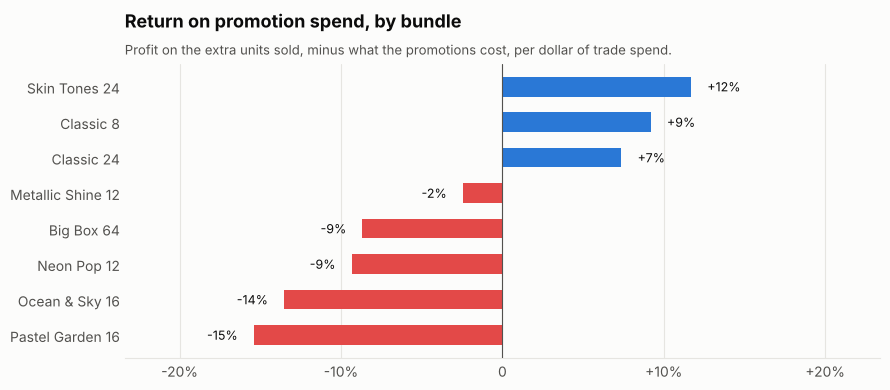

In [16]:
P.promo_roi_bars(roi.roi, names, "../reports/figures/promo_roi.png");

Promotions return a little more than they cost on **Skin Tones 24 and the two Classic sets**, and lose money on everything else. The worst are the two themed 16-packs, and **Neon Pop 12 loses about 9 cents per dollar** even though it is the most price-sensitive bundle. The discount it needs to move volume is given away on every box sold that week, including the boxes people would have bought anyway.

These verdicts depend on the trade terms, so here is the same set of promotions under different terms:

In [17]:
terms = {}
for share in (0.5, 0.35):
    for fee in (0, 3, 6):
        terms[f"{share:.0%} funded, ${fee} display"] = A.roi_under_terms(model, s, bundles, share, fee)
sens = pd.DataFrame(terms)
sens.index = names.reindex(sens.index)
sens.style.format("{:+.0%}")

,"50% funded, $0 display","50% funded, $3 display","50% funded, $6 display","35% funded, $0 display","35% funded, $3 display","35% funded, $6 display"
name,,,,,,
Classic 8,+62%,+9%,-18%,+131%,+37%,-3%
Classic 24,+34%,+7%,-10%,+92%,+41%,+12%
Pastel Garden 16,+63%,-15%,-43%,+133%,+0%,-36%
Ocean & Sky 16,+52%,-14%,-40%,+117%,+4%,-31%
Neon Pop 12,+45%,-9%,-34%,+108%,+12%,-24%
Metallic Shine 12,+121%,-2%,-37%,+216%,+12%,-32%
Skin Tones 24,+55%,+12%,-13%,+121%,+43%,+5%
Big Box 64,+25%,-9%,-28%,+79%,+17%,-13%


**The terms decide the answer.** At the current terms (50% funded, $3 display), three bundles pay back. With no display fee, or with the factory funding 35% of the discount instead of half, every bundle's promotions at least break even (Pastel Garden 16 only just). At $6 a display week with half the discount funded, none do. The negotiation with retailers is worth more than fine-tuning which bundle to promote.

> **Accounting note.** Under ASC 606 (and IFRS 15), payments to a customer such as scan-downs and display fees are generally a *reduction of revenue*, not a marketing expense, unless they buy a distinct service at fair value. `net_revenue` in this study follows that treatment: units × wholesale price, minus trade spend.

## 7. Profit and the case for distribution

Profit after trade spend, actual and like for like:

In [18]:
profit = pd.DataFrame({
    "name": names,
    "gross_profit_2yrs": naive.gross_profit,
    "gross_profit_per_store_week": naive.gross_profit / naive.store_weeks,
    "like_for_like_margin_per_store_week": like.margin_per_store_week,
}).sort_values("like_for_like_margin_per_store_week", ascending=False)
profit.round(2)

,name,gross_profit_2yrs,gross_profit_per_store_week,like_for_like_margin_per_store_week
B07,Skin Tones 24,16584.63,10.16,12.02
B02,Classic 24,50103.52,8.03,8.42
B08,Big Box 64,21750.81,6.15,4.98
B01,Classic 8,26895.59,4.31,4.50
B06,Metallic Shine 12,15908.06,5.67,3.92
B04,Ocean & Sky 16,13592.88,3.63,3.78
B03,Pastel Garden 16,13395.39,3.07,3.08
B05,Neon Pop 12,11900.44,2.24,2.53


Skin Tones 24 earns about $12 of margin per store-week like for like, roughly 40% more than Classic 24, the next best. It is on 30 of 60 shelves. So, what if it were on all of them?

In [19]:
gain = A.full_distribution_gain(model, s, bundles, "B07", year=2025)
gain.round(0)

new_store_weeks         1734.0
extra_units            17439.0
extra_gross_profit     22671.0
stores_carrying_now       30.0
dtype: float64

Had all 60 stores carried Skin Tones 24 for all of 2025, the model expects roughly **17,000 more boxes and about $22,000 more gross profit**, at regular price with no promotion. In practice some of those sales would come out of Classic 24, the other 24-crayon set (cannibalization isn't in this model or in this data), and a retailer has to give up shelf space to carry it. Treat the number as an upper bound worth testing, not a forecast.

## Recommendations

1. **Expand Skin Tones 24 distribution first.** It is the best-selling bundle like for like, the most profitable per shelf, and on only half the shelves. Start with school-supply stores, where it sells best.
2. **Stop judging bundles by total units.** Report like-for-like sales, or at least units per store-week, next to totals.
3. **Renegotiate trade terms before re-planning promotions.** Under current terms most promotions lose money; under slightly better terms most pay.
4. **Promote less, and promote the right bundles.** Cut Pastel Garden 16 and Ocean & Sky 16 promotions first. Neon Pop 12 sells on discount, but at a loss.
5. **Test a price increase on Metallic Shine 12 and Skin Tones 24**, the least price-sensitive bundles, in a few stores before rolling it out.

## 8. Checking the answers

Now, and only now, the answer key.

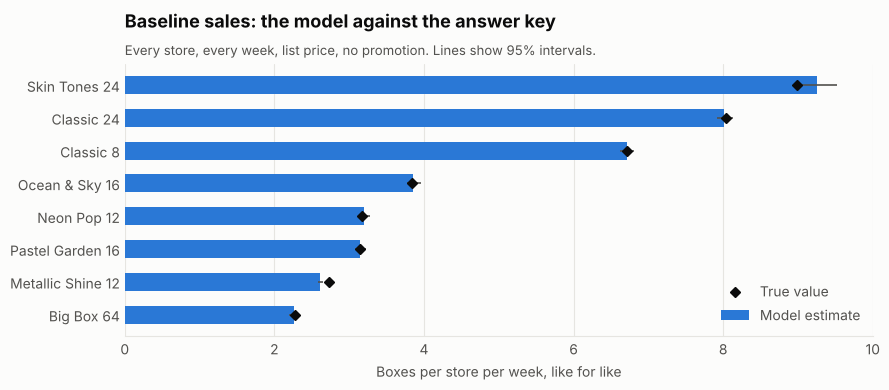

In [20]:
truth, truth_global, true_stores = A.load_truth()
P.velocity_vs_truth(ci, truth.baseline_velocity, names, "../reports/figures/velocity_vs_truth.png");

In [21]:
check = pd.DataFrame({
    "name": names,
    "true_like_for_like": truth.baseline_velocity,
    "estimate": ci.estimate, "low": ci.low, "high": ci.high,
})
check["inside_interval"] = (check.low <= check.true_like_for_like) & (check.true_like_for_like <= check.high)
check["true_rank"] = check.true_like_for_like.rank(ascending=False).astype(int)
check["model_rank"] = check.estimate.rank(ascending=False).astype(int)
check["total_units_rank"] = naive.units.rank(ascending=False).astype(int)
check.round(2)

,name,true_like_for_like,estimate,low,high,inside_interval,true_rank,model_rank,total_units_rank
B01,Classic 8,6.72,6.71,6.62,6.81,True,3,3,2
B02,Classic 24,8.03,8.02,7.92,8.13,True,2,2,1
B03,Pastel Garden 16,3.15,3.14,3.08,3.22,True,6,6,4
B04,Ocean & Sky 16,3.83,3.86,3.77,3.96,True,4,4,5
B05,Neon Pop 12,3.17,3.20,3.14,3.28,True,5,5,3
B06,Metallic Shine 12,2.73,2.61,2.58,2.65,False,7,7,7
B07,Skin Tones 24,8.99,9.25,9.02,9.53,False,1,1,6
B08,Big Box 64,2.28,2.26,2.20,2.34,True,8,8,8


The like-for-like ranking matches the true ranking exactly. Total units put only two of the eight bundles in the right place (the bottom two), and units per store-week put four.

Two estimates sit just outside their 95% intervals: Skin Tones 24 a little high, Metallic Shine 12 a little low. Both are bundles the model has to extrapolate for: Skin Tones 24 is on half the shelves, and Metallic Shine 12 is barely stocked outside big stores. The robustness check below shows this is a pattern, not bad luck.

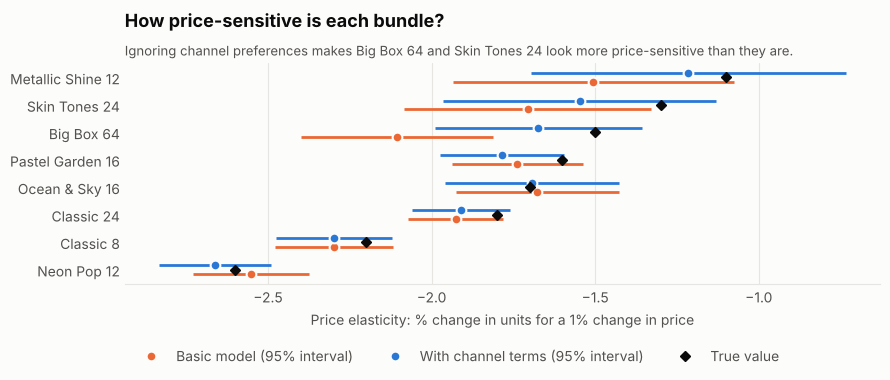

In [22]:
P.elasticity_dots({"Basic model": basic.elasticities(), "With channel terms": model.elasticities()},
                  truth.elasticity, names, "../reports/figures/elasticities.png");

In [23]:
lo, mid_lo, hi = model.display_lift()
print(f"Display lift: estimated {lo:.3f} (95% interval {mid_lo:.3f} to {hi:.3f}), "
      f"true {truth_global['display_lift']:.3f}")
true_roi = A.true_promo_roi(s, bundles, truth, true_stores)
pd.DataFrame({"name": names, "estimated_roi": roi.roi, "true_roi": true_roi}).round(3)

Display lift: estimated 1.495 (95% interval 1.439 to 1.554), true 1.500


,name,estimated_roi,true_roi
bundle_id,,,
B01,Classic 8,0.092,0.085
B02,Classic 24,0.074,0.066
B03,Pastel Garden 16,-0.154,-0.155
B04,Ocean & Sky 16,-0.135,-0.132
B05,Neon Pop 12,-0.093,-0.088
B06,Metallic Shine 12,-0.024,-0.024
B07,Skin Tones 24,0.117,0.149
B08,Big Box 64,-0.087,-0.095


Promotion ROI is within about 3 points of the truth on every bundle, with the same sign on all eight.

### Is this dataset lucky?

One dataset is one draw: which stores happened to carry what, which weeks were noisy. `src/robustness.py` regenerates the sales 20 times with different seeds (same company and true demand, different assortment, promotions and noise) and reruns everything with the same code and no retuning. It takes several minutes, so its results are saved and read here.

In [24]:
rob = pd.read_csv("../reports/robustness.csv")
summary = pd.DataFrame({
    "total units": [rob.rank_corr_total_units.mean(), rob.top_pick_total_units.mean(), np.nan, np.nan],
    "units per store-week": [rob.rank_corr_velocity.mean(), rob.top_pick_velocity.mean(), np.nan, np.nan],
    "basic model": [rob.basic_rank_corr.mean(), rob.basic_top_pick.mean(),
                    rob.basic_elasticity_ci_coverage.mean(), rob.basic_elasticity_mean_abs_error.mean()],
    "with channel terms": [rob.channel_rank_corr.mean(), rob.channel_top_pick.mean(),
                           rob.channel_elasticity_ci_coverage.mean(),
                           rob.channel_elasticity_mean_abs_error.mean()],
}, index=["rank correlation with the truth", "picks the true best bundle",
          "elasticity intervals that contain the truth", "elasticity mean absolute error"])
summary.round(3)

,total units,units per store-week,basic model,with channel terms
rank correlation with the truth,0.6,0.90,0.990,0.986
picks the true best bundle,0.0,0.05,1.000,1.000
elasticity intervals that contain the truth,NaN,NaN,0.762,0.906
elasticity mean absolute error,NaN,NaN,0.172,0.122


In [25]:
rob[["channel_baseline_ci_coverage", "channel_roi_sign_agreement", "channel_roi_mean_abs_error"]] \
    .agg(["mean", "min", "max"]).round(3)

,channel_baseline_ci_coverage,channel_roi_sign_agreement,channel_roi_mean_abs_error
mean,0.844,0.994,0.012
min,0.625,0.875,0.005
max,1.000,1.000,0.021


Across 20 datasets:

- **Total units never picked the true best bundle**, and its ranking correlates only about 0.6 with the truth. Units per store-week does better (about 0.9) but picked the true best bundle in 1 of 20.
- **Both models picked the true best bundle every time**, with a rank correlation of about 0.99.
- **The channel terms are what make the price answers trustworthy.** Elasticity error falls from 0.17 to 0.12, and the share of 95% intervals that contain the true elasticity rises from 76% to 91%.
- **They also cost something.** The channel model's intervals for like-for-like sales contain the truth only 84% of the time, against 96% for the basic model. It has to extrapolate to bundle-channel combinations that were rarely or never stocked, and with only 60 stores the robust intervals don't fully reflect that uncertainty. So: use the channel model for prices and promotions, and read its like-for-like intervals as somewhat too narrow.
- **Promotion ROI** has the right sign 99% of the time and is off by about one point on average.

## 9. Limits

- **The same author wrote the data generator and the model.** The channel effects were added specifically so the model would be wrong in a realistic way, but real demand has more going on than any generator: substitution between bundles, stockouts, competitors, retailer pricing rules. These results show the method working, not how precise it would be on real data.
- **No cannibalization.** The model treats each bundle's sales as independent. Expanding Skin Tones 24 would take some sales from Classic 24, and the distribution gain is an upper bound.
- **Sell-through is treated as sell-in.** The factory is paid when retailers buy, not when shoppers do. Inventory timing is ignored.
- **Some intervals are too narrow.** With 60 stores to cluster on, robust standard errors run optimistic: elasticity intervals cover the truth 91% of the time and like-for-like intervals 84%, for a nominal 95%. A wild cluster bootstrap would fix this at some cost in run time.
- **Untested combinations are assumptions.** Big Box 64 has never been in a drugstore. What it would sell there is the model's guess, not data.

## 10. Next steps

- Add cross-effects between bundles, starting with Classic 24 and Skin Tones 24, to measure cannibalization before expanding distribution.
- Model the post-promotion dip: weeks after a promotion often sell less because shoppers stocked up, which would make promotion ROI look worse than it does here.
- Run a controlled test: add Skin Tones 24 to a random half of the stores that don't carry it, and compare with the other half.